# A notebook to generate EOS tables and set up the JCD model S to be operational with DISPATCH.
This notebook contains all the required procedures, that generate the required data for the whole Sun experiment.
It is recommended to leave the default paths, but they of course can be changed if needed. Do remember to set up the right paths for 'top' of the DISPATCH repository

## Set up paths
### Add more cells as needed, and convert the one you want from raw to code

Andrius:

Åke:

In [1]:
top='/groups/astro/aake/codes/dispatch2/'

Mikolaj, `*.uio.no`

# Import required libraries

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import sys
import numpy as np
import matplotlib.pyplot as pl
import astropy
from astropy import constants as SI

In [4]:
lib=top+'utilities/python'
if lib not in sys.path:
    sys.path.insert(0,lib)
import dispatch
import dispatch.solar_models
import dispatch.EOS
from dispatch.EOS import interp

## As a first step, we need to generate the EOS tables. 
We use EOS tables, made by Kengo Tomida and Yasunori Hori,  Jul. 1st ,2016., private communication. Not to be shared publicly without permission. The following routines will generate itable DISPATCH EOS, which can be used with microphysics/eos/itable EOS during runtime.

In [5]:
os.chdir(top+'data/eos/') # Go to the folder, containig the original data file

In [6]:
eos=dispatch.EOS.tomida(top=top,verbose=1)
# Add Rosseland and Planck mean opacities to tables
eos.add_opac()
print('scale 0:', eos.scale0.name)
print('scale 1:', eos.scale1.name)
print('-- variables and their indices in the dict--')
eos.variables


variables: {0: 'P', 1: 'ln(ee)', 2: 'C_T', 3: 'cs', 4: 'gamma', 5: 'Cv'}
reading file /groups/astro/aake/codes/dispatch2/data/opacities/Tomida+Hori_2016/kr.dat
reading file /groups/astro/aake/codes/dispatch2/data/opacities/Tomida+Hori_2016/kp.dat
scale 0: ln(rho)
scale 1: ln(T)
-- variables and their indices in the dict--


{0: 'P', 1: 'ln(ee)', 2: 'C_T', 3: 'cs', 4: 'gamma', 5: 'Cv', 6: 'kr', 7: 'kp'}

In [7]:
# Convert table to ln(ee), add entropy
eosE=eos.lnT_to_lnee(verbose=1)
eosE.add_S()
print ('scale 0:', eosE.scale0.name)
print ('scale 1:',eosE.scale1.name)
print ('-- variables and their indices in the dict--')
eosE.variables

scale 0: ln(rho)
scale 1: ln(ee)
-- variables and their indices in the dict--


{0: 'P',
 1: 'T',
 2: 'C_T',
 3: 'cs',
 4: 'gamma',
 5: 'Cv',
 6: 'kr',
 7: 'kp',
 8: 'S'}

In [8]:
#Write out the table
eosE.write('dispatch_tomida.eos',verbose=1)

## Now we are ready to set up the JCD model S.

#### Change the working directory

In [9]:
os.chdir(top+'data/solar_models')

#### Read in the model S and test.

In [10]:
model=dispatch.solar_models.JCD_S(top=top)
r=model.r
T=model.T
d=model.rho

#### Test the EOS tables.

In [11]:
w=np.where(r<1)[0][0]
r0=r[w]; d0=d[w]; T0=T[w]
r0,d0,T0

(0.9999965, 2.0253139e-07, 5800.4406)

In [12]:
#test tables
print ('Testing ln(T) based EOS')
ee=np.exp(eos.lookup('ln(ee)',np.log(d0),np.log(T0)))
print('d={:.3e} T={:.3e} ee={:.3e}'.format(d0,T0,ee))
T0 = np.exp(eos.inverse_lookup('ln(ee)', np.log(d0), np.log(ee)))
print('d={:.3e} T={:.3e} E={:.3e}'.format(d0, T0, ee))
print('Testing ln(ee) based EOS')
T0 = eosE.lookup('T', np.log(d0), np.log(ee))
print('d={:.3e} T={:.3e} E={:.3e}'.format(d0, T0, ee))
ee = np.exp(eosE.inverse_lookup('T', np.log(d0), T0))
print('d={:.3e} T={:.3e} ee={:.3e}'.format(d0, T0, ee))


Testing ln(T) based EOS
d=2.025e-07 T=5.800e+03 ee=2.058e+12
d=2.025e-07 T=5.800e+03 E=2.058e+12
Testing ln(ee) based EOS
d=2.025e-07 T=5.801e+03 E=2.058e+12
d=2.025e-07 T=5.801e+03 ee=2.058e+12


### Work on JCD Model-S

#### Integrated mass

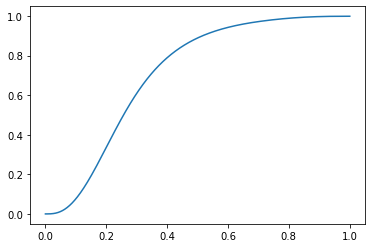

In [13]:
model=dispatch.solar_models.JCD_S(top=top)
M=[]
dM=[]
m=0.0
R_sun=SI.R_sun.cgs.value
M_sun=SI.M_sun.cgs.value
c=4.*np.pi*R_sun**3
M.append(M_sun*0.99905)
for i in range(1,len(model.r)):
    dm=c*(model.rho[i-1]*model.r[i-1]**2+model.rho[i]*model.r[i]**2)*(model.r[i-1]-model.r[i])/2
    dM.append(dm)
    m=m+dm
    M.append(M[0]-m)

M=np.where(np.array(M) > 0., M, 0)
pl.plot(model.r,M/M_sun);

#### Acceleration of gravity

log10(g) = 4.44


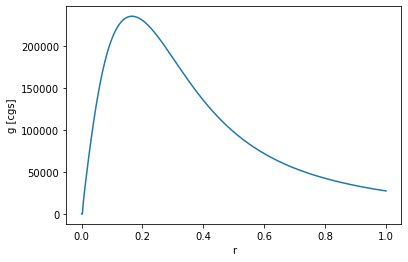

In [14]:
g=SI.G.cgs.value*M/(model.r+1e-20)**2/SI.R_sun.cgs.value**2
pl.plot(model.r,g); pl.xlabel('r'); pl.ylabel('g [cgs]');
print('log10(g) = {:.2f}'.format(np.log10(g[0])))
g0=np.copy(g)
r0=np.copy(model.r)

### Entropy profile of Model S with Tomida & Hori EOS

In [15]:
def lookup(name,d,E):
  return eosE.lookup(name, np.log(d), np.log(E))
def inverse_lookup(name,d,v):
  return np.exp(eosE.inverse_lookup(name,np.log(d),v))

In [16]:
model=dispatch.solar_models.JCD_S(top=top)

Entropy S from table lookup

In [17]:
S=[]
#S.append(0.0)
n=1600
S=np.zeros(n)
r=model.r[0:n]
R=r*R_sun
d=model.rho[0:n]
T=model.T[0:n]
E=np.zeros(n)
for i in range(0,n):
    E[i]=inverse_lookup('T',d[i],T[i])
P=lookup('P',d,E)
S=lookup('S',d,E)

Entropy S2 from integration:

In [18]:
S2=[]
S2.append(S[0])
for i in range(1,n):
    dlnd=np.log(d[i]/d[i-1])
    Pd=(P[i-1]+P[i])/(d[i-1]+d[i])
    Ta=0.5*(T[i-1]+T[i])
    dE=E[i]-E[i-1]
    S0=S[i-1]+(dE-Pd*dlnd)/Ta
    S2.append(S0)
S2=np.array(S2)

In [19]:
S2=S2-S2[-1]+S[-1]

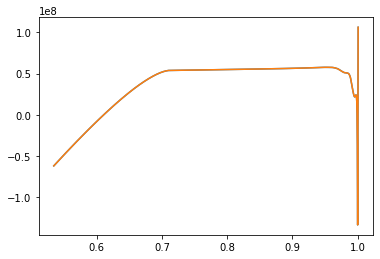

In [20]:
pl.plot(r,S)
pl.plot(r,S2);

1430

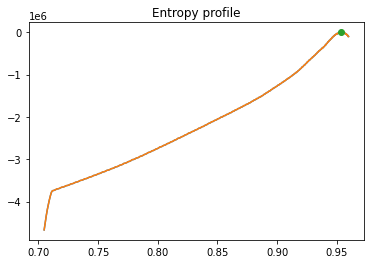

In [21]:
w=np.where((r > 0.704) & (r<0.96))
i0 = np.where(S == S[w].max())[0][0]
S=S-S[i0]
S2=S2-S2[i0]
pl.plot(r[w],S[w],'-')
pl.plot(r[w],S2[w],'-')
pl.plot(r[i0],S[i0],'o');
pl.title('Entropy profile')
w[0][-1]

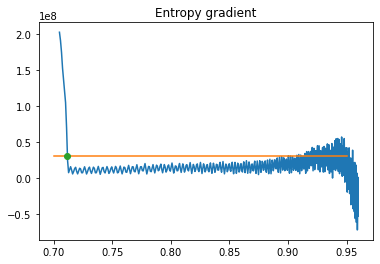

In [22]:
dSdr0=3e7
dSdr=np.gradient(S,r)
w1=np.where(dSdr[-1:0:-1] < dSdr0)[0][0]
pl.plot(r[w],dSdr[w],'-');
pl.plot([0.7,0.95],[dSdr0,dSdr0])
pl.plot(r[-w1],dSdr0,'o')
pl.title('Entropy gradient');

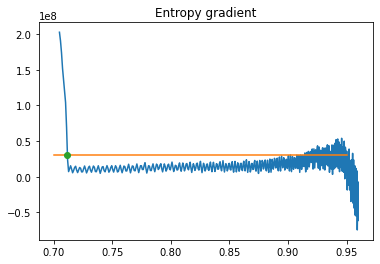

In [23]:
dSdr=np.gradient(S2,r)
w1=np.where(dSdr[-1:0:-1] < dSdr0)[0][0]
pl.plot(r[w],dSdr[w],'-');
pl.plot([0.7,0.95],[dSdr0,dSdr0])
pl.plot(r[-w1],dSdr0,'o')
pl.title('Entropy gradient');

So, 1e7 is a good trigger for leaving the adiabat; let's find the index, using a reversed search:

In [24]:
w1=np.where(dSdr[-1:0:-1] < dSdr0)
w1=w1[0][0]

### Re-integration of hydrostatic balance, with constant entropy in the CZ below peak entropy

In [25]:
r[i0],r[w1]

(0.9534665, 0.999742)

In [26]:
S1=np.copy(S)
R=r*R_sun
G0=SI.G.cgs.value
c=4*np.pi
print ('original bottom radius', r[-1])
print('isentropic from index',i0)
verbose=0
i1=0
if verbose>0:
    n1=i0+4
else:
    n1=len(r)
for i in range(i0+1-10,n1):
    dlnd=np.log(d[i]/d[i-1])                                                    # step in ln(d) (constant)
    da=(d[i]+d[i-1])/2                                                          # average density (constant)
    g1=G0*M[i-1]/r[i-1]**2                                                      # first guess
    Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                              # first guess
    dE=Pd*dlnd                                                                  # adiabatic enery increment
    E[i]=E[i-1]+dE                                                              # new internal energy
    M[i]=M[i-1]

    # as long as dSdr stays below the trigger value, enforce constant S
    if i < n1-w1:
        # iterate to constant entropy and exact hydrostatic balance
        for iter in range(1):
            T[i]=lookup('T',d[i],E[i])                                          # new temperature
            P[i]=lookup('P',d[i],E[i])                                          # new pressure
            if verbose>2:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))
            Ta=(T[i-1]+T[i])/2                                                  # new average temperature
            if verbose>3: print('Ta',Ta)
            Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                      # new average P/d
            if verbose>3: print('Pd',Pd)
            dP=P[i]-P[i-1]                                                      # P increment (positive)
            g1=G0*(M[i]/R[i]**2+M[i-1]/R[i-1]**2)/2                             # acc. of gravity
            if verbose>3: print(' g',g)
            if verbose>3: print('da',da)
            dR=-dP/(g1*da)                                                      # radius increment (negative)
            if verbose>3: print('dr',dr)
            R[i]=R[i-1]+dR                                                      # new radius
            dM=c*(d[i-1]*R[i-1]**2+d[i]*R[i]**2)*dR/2                           # dm = change in mass
            M[i]=M[i-1]+dM                                                      # new mass at [i]
            dE=Pd*dlnd                                                          # adiabatic enery increment
            E[i]=E[i-1]+dE                                                      # new internal energy
            if verbose>1:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))
        Sprv=S1[i]
        S1[i]=S1[i-1]
        r[i]=R[i]/R_sun
    # after that, just adjust with the accumulated shift, and recompute
    else:
        if i1==0:
            i1=i
            print('switch to stable layer at index:',i1,' radius:',r[i1])
        S1[i]=S1[i]-Sprv
        dS=S1[i]-S1[i-1]                                                          # new dS
        Ta=(T[i-1]+T[i])/2                                                      # average temperature
        # iterate to exact hydrostatic balance
        for iter in range(200):
            dE=Pd*dlnd+dS/Ta                                                    # internal energy incr
            E[i]=E[i-1]+dE                                                      # new internal energy
            T[i] = lookup('T', d[i], E[i])                                      # new temperature
            P[i] = lookup('P', d[i], E[i])                                      # new pressure
            Ta=(T[i-1]+T[i])/2                                                  # new average temperature
            Pd=(P[i-1]+P[i])/(d[i-1]+d[i])                                      # new average P/d
            dP=P[i]-P[i-1]                                                      # P increment (positive)
            g1=G0*(M[i]/R[i]**2+M[i-1]/R[i-1]**2)/2                             # acc. of gravity
            dR=-dP/(g1*da)                                                      # radius increment (negative)
            R[i]=R[i-1]+dR                                                      # new radius
            dM=c*(d[i-1]*R[i-1]**2+d[i]*R[i]**2)*dR/2                           # dm = change in mass
            M[i]=M[i-1]+dM                                                      # new mass at [i]
            if verbose>1:
                print('{:3d} {:3d} {:14.8f} {:14.5e} {:14.5e} {:14.5e}'.format(i,iter,r[i],d[i],P[i],T[i]))

    r[i]=R[i]/R_sun
    g[i]=G0*M[i]/R[i]**2
    if verbose > 0:
        print(i,r[i],S1[i])
print('new bottom radius:',r[-1])

original bottom radius 0.5341805
isentropic from index 972
switch to stable layer at index: 1423  radius: 0.7109138
new bottom radius: 0.44909496159963114


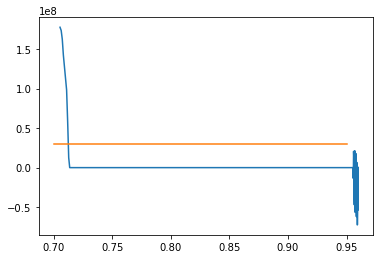

In [27]:
dSdr = np.gradient(S1, r)
pl.plot(r[w], dSdr[w], '-')
pl.plot([0.7, 0.95], [dSdr0, dSdr0]);

#### Entropy profile below CZ

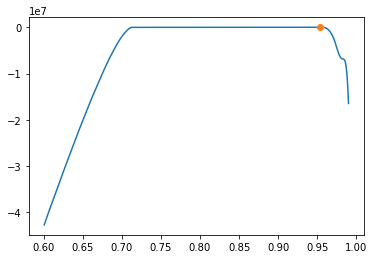

In [28]:
w=np.where((r < 0.99) & (r > 0.60))
pl.plot(r[w],S1[w],'-');
pl.plot(r[i0],S1[i0],'o');

#### New mass profile

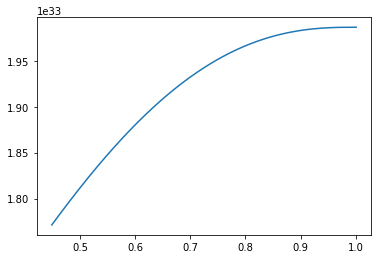

In [29]:
pl.plot(r,M[0:len(r)]);

#### New acceleration of gravity profile

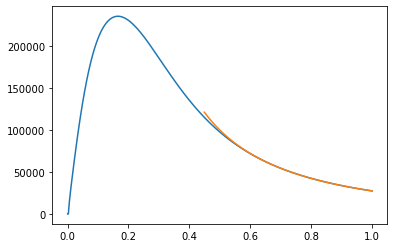

In [30]:
pl.plot(r0,g0);
pl.plot(r,g[0:len(r)]);

## Write out .tbl file for DISPATCH, in CGS units

In [31]:
n=len(r)
idx=[0.1,5]
file='JCD-model-S2.tbl'
with open(file,'w') as fd:
    fd.write('{} {}\n'.format(n,len(idx)))
    for i in range(n):
        line='{:12.8f} {:18.8e} {:18.8e} {:18.8e} {:18.8e}\n'.format(r[i],g[i],d[i],E[i],T[i])
        fd.write(line)

In [32]:
from scipy.io import FortranFile

In [33]:
n=len(r)
idx=[0.1,5]
file='JCD-model-S2.dat'
with FortranFile(file,'w') as fd:
    fd.write_record(n,len(idx))
    for i in range(n-1,-1,-1):
        fd.write_record(r[i],g[i],d[i],E[i],T[i])

#### Check the change in adiabatic index over the atmosphere

In [34]:
gamma=np.zeros(n)
for i in range(n-1):
  gamma[i]=eosE.lookup('gamma',np.log(d[i]),np.log(E[i]))

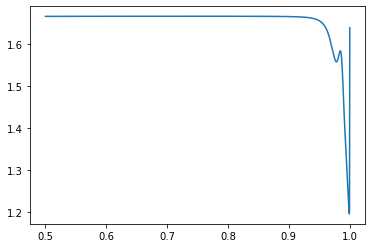

In [35]:
w=np.where((r < 1.0) & (r > 0.50))
pl.plot(r[w],gamma[w]);

It would seem we need to use variable \gamma at the top of the atmosphere